# Using Spacy

In [4]:
!pip install -U pip setuptools wheel
!python -m spacy download en_core_web_sm
!pip install spacy==3.7.5
!pip install scispacy
!pip install gensim
%cd /Users/led7283981/Downloads/mimic-iii-clinical-database-1.4

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 14.5 MB/s eta 0:00:00a 0:00:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
/Users/led7283981/Downloads/mimic-iii-clinical-database-1.4


In [2]:
import pandas as pd
pd.options.mode.chained_assignment = None
import numpy as np
import re

from gensim.models import word2vec

from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
import spacy
nlp = spacy.load('en_core_web_sm')

In [5]:
notes = []
with open('df_4019_nutrition_notes_limited.txt', 'r') as fin:
  lines = fin.readlines()
  for line in lines:
    notes.append(line)
print(notes)
print(len(notes))

['Subjective\n', '   Patient with trach, did not tolerate trach collar trial\n', '   Objective\n', '   Pertinent medications: RISS, multivitamin, colace, lactulose,\n', '   prednisone\n', '   Labs:\n', '   Value\n', '   Date\n', '   Glucose\n', '   147 mg/dL\n', '   [**2139-7-7**] 01:18 AM\n', '   Glucose Finger Stick\n', '   193\n', '   [**2139-7-7**] 06:00 AM\n', '   BUN\n', '   54 mg/dL\n', '   [**2139-7-7**] 01:18 AM\n', '   Creatinine\n', '   3.6 mg/dL\n', '   [**2139-7-7**] 01:18 AM\n', '   Sodium\n', '   130 mEq/L\n', '   [**2139-7-7**] 01:18 AM\n', '   Potassium\n', '   3.6 mEq/L\n', '   [**2139-7-7**] 01:18 AM\n', '   Chloride\n', '   100 mEq/L\n', '   [**2139-7-7**] 01:18 AM\n', '   Albumin\n', '   3.0 g/dL\n', '   [**2139-7-3**] 03:43 AM\n', '   Calcium non-ionized\n', '   7.9 mg/dL\n', '   [**2139-7-7**] 01:18 AM\n', '   Phosphorus\n', '   1.9 mg/dL\n', '   [**2139-7-7**] 01:18 AM\n', '   Ionized Calcium\n', '   1.18 mmol/L\n', '   [**2139-7-4**] 05:47 AM\n', '   Magnesium\

In [6]:
df=notes

In [7]:
# Build corpus of all the entities extracted from the notes using spaCy model.
# The corpus is an array of arrays or list of lists where each of the nested lists corresponds to a note.
corpus=[]
for row in range(0, len(df)):
  str_tokens=[]
  tokens= nlp(df[row]).ents
  for i in range(0, len(tokens)):
    str_tokens.append(tokens[i].text)
  corpus.append(list(str_tokens))


print(corpus)

[[], [], [], [], [], [], [], [], [], ['147'], ['2139-7-7', '01:18 AM\n'], ['Stick'], [], ['2139-7-7', '06:00 AM'], ['BUN'], [], ['2139-7-7', '01:18 AM\n'], [], ['3.6'], ['2139-7-7', '01:18 AM\n'], [], [], ['2139-7-7', '01:18 AM\n'], [], ['3.6 mEq'], ['2139-7-7', '01:18 AM\n'], [], [], ['2139-7-7', '01:18 AM\n'], [], ['3.0'], ['2139-7-3', '03:43 AM\n'], [], ['7.9'], ['2139-7-7', '01:18 AM\n'], [], [], ['2139-7-7', '01:18 AM\n'], ['Ionized Calcium\n'], ['1.18'], ['2139-7-4'], [], [], ['2139-7-7', '01:18 AM\n'], ['Nutren Renal', '30'], ['30ml', '76'], [], [], [], ['69 year old', 'COPD', 'CHF'], ['PNA'], ['ARF'], [], [], [], [], ['Nutren Renal', '30', '30ml'], ['24 hours'], [], ['3'], [], [], [], [], [], [], [], [], [], [], ['114'], ['2139-7-13', '02:19 AM\n'], ['Stick'], ['115'], ['2139-7-12', '12:00 PM'], ['BUN'], [], ['2139-7-13', '02:19 AM\n'], [], ['3.9'], ['2139-7-13', '02:19 AM\n'], [], [], ['2139-7-13', '02:19 AM\n'], [], ['4.3 mEq'], ['2139-7-13', '02:19 AM\n'], [], [], ['2139-7-1

The vectors generated by Word2Vec, as implemented by the Gensim library, are specific to the corpus used for training. Word2Vec learns word embeddings by analyzing the patterns of word co-occurrence within the given training corpus. As a result, the learned word vectors capture the semantics and relationships of words as they appear in that particular corpus.

In other words, the word embeddings produced by Word2Vec are not universal but are context-dependent. They represent how words are related to each other within the specific textual data provided during training. Therefore, if you train a Word2Vec model on one corpus and then train another model on a different corpus, the word vectors learned by each model may differ because they reflect the linguistic patterns and context of their respective training data.

To create word vectors that are more general and applicable across different contexts, larger and more diverse training corpora are often used. Pretrained Word2Vec models, such as those trained on massive text datasets like Wikipedia or news articles, offer word vectors that are more general and can be used as a starting point for various natural language processing tasks. These pretrained embeddings capture a broad range of linguistic knowledge from diverse sources, making them useful in many applications.

In summary, Word2Vec word vectors are specific to the training corpus but can be made more universal by training on larger and more diverse datasets or by using pretrained embeddings.

In [8]:
from gensim.models import Word2Vec
model1 = Word2Vec(corpus, min_count=1)

The output shows words that are not semantically similar to "Tylenol." This can happen if the training data used to train the Word2Vec model does not contain enough context or examples of the word "Tylenol" and its related terms, or if the model's parameters (such as min_count) are not set appropriately.

In this case since Tylenol appears only once in the entire corpus, min_count has to be set to 1. (The model ignores all words that appear less than min_count times)

This comes at a cost, means that even very infrequent words are included in the vocabulary. This can lead to noisy word embeddings for rare words.

In [13]:
def tsne_plot(model,words, preTrained=False):
    "Creates and TSNE model and plots it"
    labels = []
    tokens = []

    for word in words:
      if preTrained:
          tokens.append(model[word])
      else:
          tokens.append(model.wv[word])
      labels.append(word)

    tokens = np.array(tokens)
    tsne_model = TSNE(perplexity=30, early_exaggeration=12, n_components=2, init='pca', n_iter=1000, random_state=23)
    new_values = tsne_model.fit_transform(tokens)

    x = []
    y = []
    for value in new_values:
        x.append(value[0])
        y.append(value[1])

    plt.figure(figsize=(16, 16))
    for i in range(len(x)):
        plt.scatter(x[i],y[i])
        plt.annotate(labels[i],
                     xy=(x[i], y[i]),
                     xytext=(5, 2),
                     textcoords='offset points',
                     ha='right',
                     va='bottom')
    plt.show()

/opt/anaconda3/lib/python3.12/site-packages/sklearn/manifold/_t_sne.py:1162: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


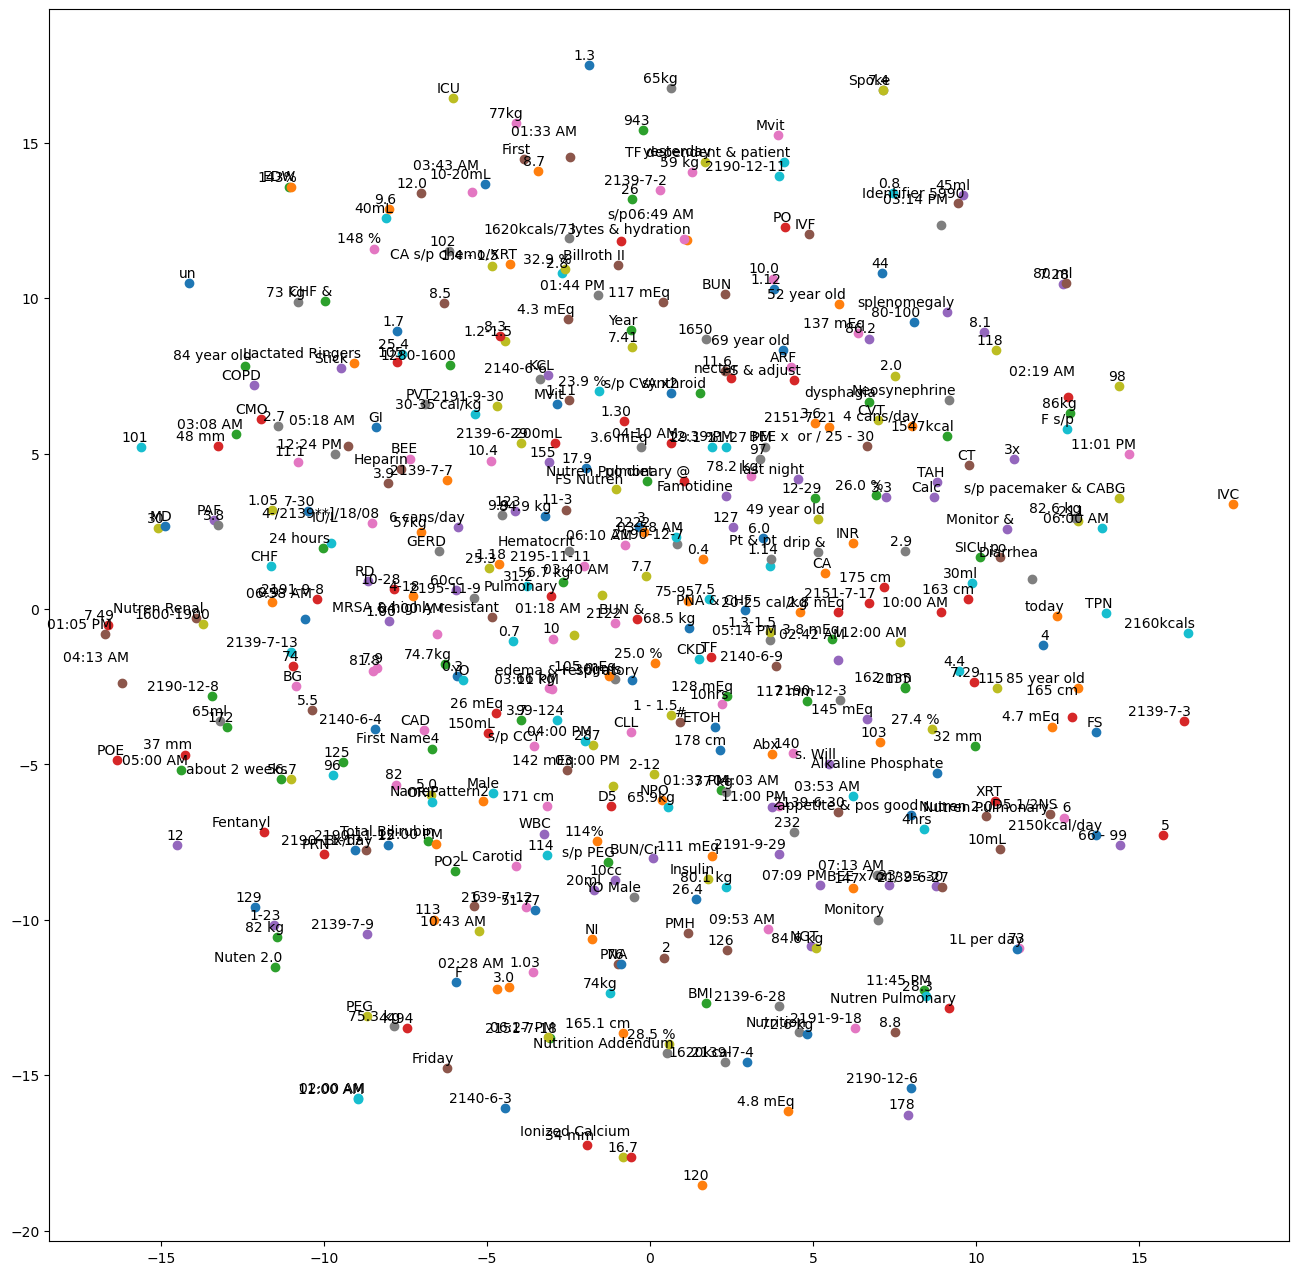

In [14]:
vocabs = model1.wv.key_to_index.keys()
new_v = np.array(list(vocabs))
tsne_plot(model1,new_v)

In [17]:
# load pre-trained word2vec embeddings
import gensim
import gensim.downloader as api

info = api.info()  # show info about available models/datasets
pretrained_model= api.load("glove-wiki-gigaword-50")  # download the model and return as object ready for use


# pretrained_model = gensim.models.KeyedVectors.load_word2vec_format('PubMed-and-PMC-ri.tar.gz', binary=True)

In [19]:
corpus_in_pretrained_model = []
for word in vocabs:
  if word in pretrained_model:
    corpus_in_pretrained_model.append(word)
  else:
    print(word) #

2190-11-15
06:49 AM

2151-7-18
TF
Stick
BUN
2195-11-11
2190-12-7
2191-9-30
2190-12-11
2190-11-17
02:28 AM

24 hours
Nutren Pulmonary
02:42 AM

01:33 AM

04:00 AM

2139-6-28
Ionized Calcium

03:58 AM
2151-7-21
05:00 AM
02:19 AM

2139-7-9
2140-6-9
2139-7-2
2140-6-6
03:40 AM

2139-7-13
2140-6-4
2139-7-7
03:08 AM
04:10 AM
WBC
05:18 AM

06:10 AM
Hematocrit
01:18 AM

03:53 AM
GI
NPO
BMI
PRN
45ml
Nutren Renal
07:13 AM
CHF
2140-6-3
2190-12-8
PO
Calc
PMH
09:53 AM
2195-11-9
1.2-1.5
TPN
2190-12-6
3.8 mEq
2151-7-17
BEE x  or / 25-30
Identifier 5990
1620kcal
06:27 PM
40mL
Alkaline Phosphate
CA
Total Bilirubin
10:00 AM
COPD
04:13 AM

ARF
05:14 PM
PEG
30ml
69 year old
12:00 PM
PO2
2139-7-3
11:27 PM
03:00 PM

06:00 AM
2139-7-4
11:45 PM
03:43 AM

ICU
12:39 PM
EDW
150mL
NGT
142 mEq
11:00 PM
2190-12-3
NI
84 year old
PVT
ETOH
25.0 %
01:33 PM
04:03 AM

75.3 kg
80.1 kg
178 cm
1547kcal
175 cm
2191-9-29
CT
CAD
YO Male
10-20mL
CA s/p chemo/XRT
First Name4
Friday
148 %
49 year old
Male
PNA & CHF
po diet
2.8 mEq

/opt/anaconda3/lib/python3.12/site-packages/sklearn/manifold/_t_sne.py:1162: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


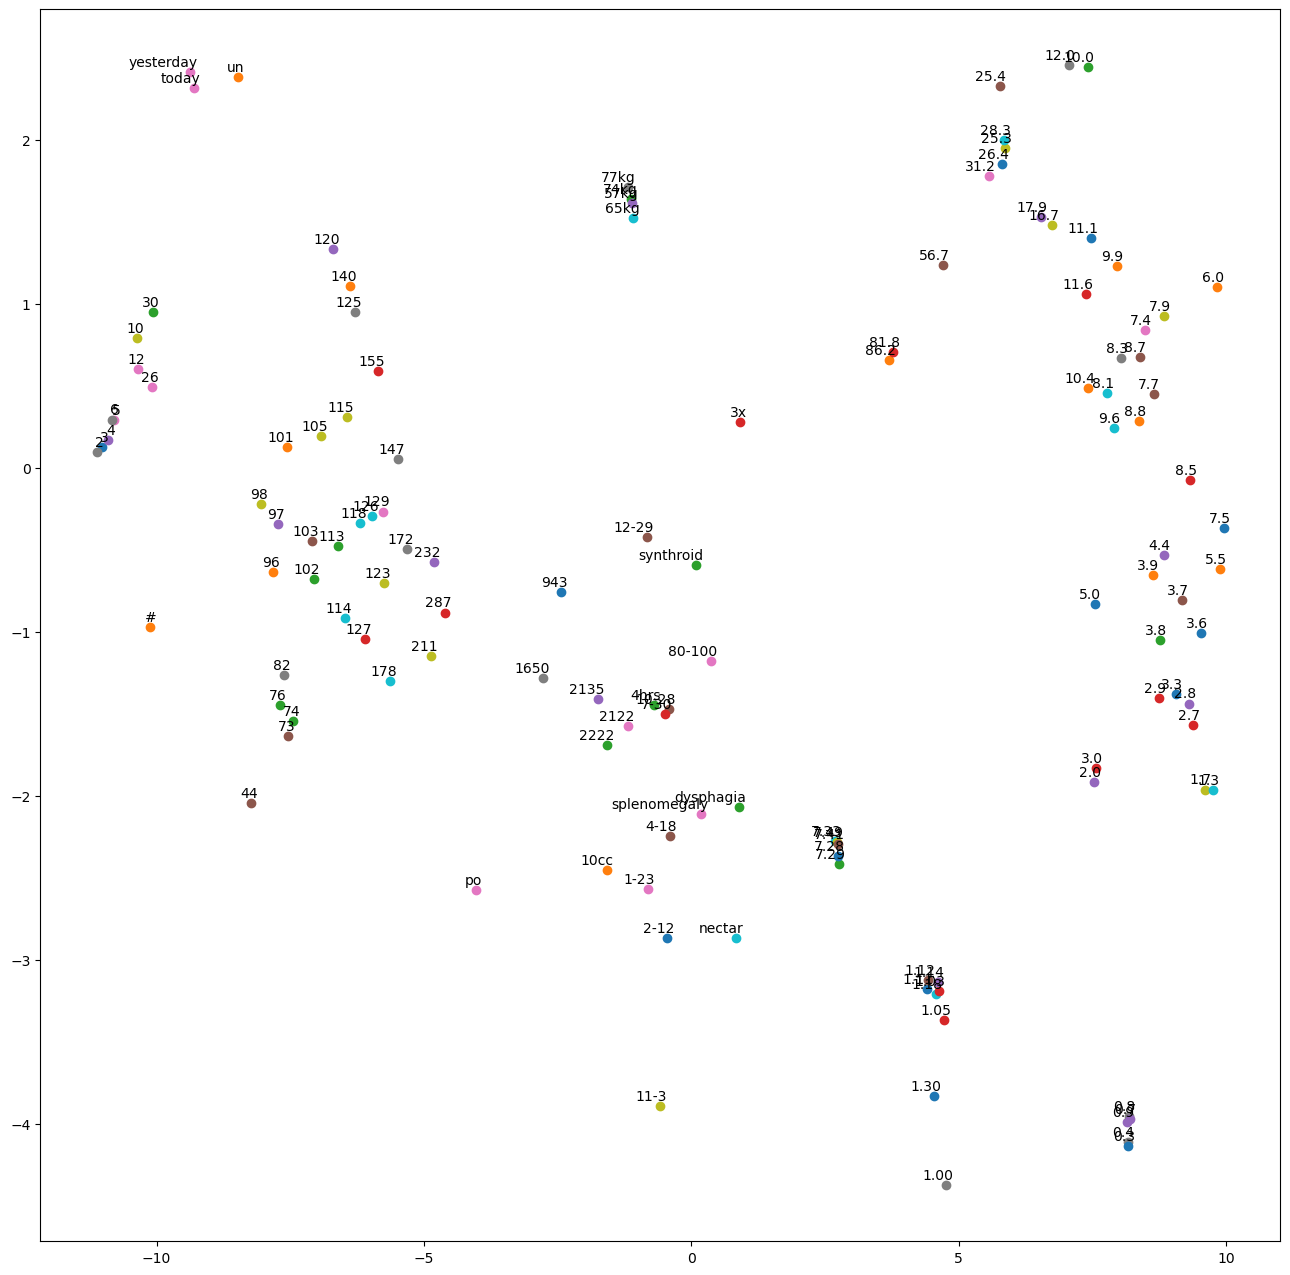

In [20]:
tsne_plot(pretrained_model,corpus_in_pretrained_model,True)

# Using SciSpacy

In [21]:
!pip install https://s3-us-west-2.amazonaws.com/ai2-s2-scispacy/releases/v0.5.4/en_ner_bc5cdr_md-0.5.4.tar.gz

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.8/119.8 MB 8.1 MB/s eta 0:00:0000:0100:01
  Preparing metadata (setup.py) ... done
  DEPRECATION: Building 'en_ner_bc5cdr_md' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'en_ner_bc5cdr_md'. Discussion can be found at https://github.com/pypa/pip/issues/6334
  Created wheel for en_ner_bc5cdr_md: filename=en_ner_bc5cdr_md-0.5.4-py3-none-any.whl size=119787714 sha256=c7456928649c2cff099a694dea4b1d9fbd2d9f6e4387e178ecb4342ca82b922f
  Stored in directory: /Users/led7283981/Library/Caches/pip/wheels/40/f3/2b/51cee972ff42cbe21ddaf5abef7376bb35c2c2ca26a96220b8
Successfully built en_ner_bc5cdr_md


In [22]:
import scispacy
import spacy

nlp = spacy.load("en_ner_bc5cdr_md")

/opt/anaconda3/lib/python3.12/site-packages/spacy/language.py:2195: FutureWarning: Possible set union at position 6328
  deserializers["tokenizer"] = lambda p: self.tokenizer.from_disk(  # type: ignore[union-attr]


In [23]:
notes = []
with open('df_4019_nutrition_notes_limited.txt', 'r') as fin:
  lines = fin.readlines()
  for line in lines:
    notes.append(line)
print(notes)
print(len(notes))

['Subjective\n', '   Patient with trach, did not tolerate trach collar trial\n', '   Objective\n', '   Pertinent medications: RISS, multivitamin, colace, lactulose,\n', '   prednisone\n', '   Labs:\n', '   Value\n', '   Date\n', '   Glucose\n', '   147 mg/dL\n', '   [**2139-7-7**] 01:18 AM\n', '   Glucose Finger Stick\n', '   193\n', '   [**2139-7-7**] 06:00 AM\n', '   BUN\n', '   54 mg/dL\n', '   [**2139-7-7**] 01:18 AM\n', '   Creatinine\n', '   3.6 mg/dL\n', '   [**2139-7-7**] 01:18 AM\n', '   Sodium\n', '   130 mEq/L\n', '   [**2139-7-7**] 01:18 AM\n', '   Potassium\n', '   3.6 mEq/L\n', '   [**2139-7-7**] 01:18 AM\n', '   Chloride\n', '   100 mEq/L\n', '   [**2139-7-7**] 01:18 AM\n', '   Albumin\n', '   3.0 g/dL\n', '   [**2139-7-3**] 03:43 AM\n', '   Calcium non-ionized\n', '   7.9 mg/dL\n', '   [**2139-7-7**] 01:18 AM\n', '   Phosphorus\n', '   1.9 mg/dL\n', '   [**2139-7-7**] 01:18 AM\n', '   Ionized Calcium\n', '   1.18 mmol/L\n', '   [**2139-7-4**] 05:47 AM\n', '   Magnesium\

In [24]:
df=notes

In [25]:
# Build corpus of all the entities extracted from the notes using spaCy model.
# The corpus is an array of arrays or list of lists where each of the nested lists corresponds to a note.
corpus=[]
for row in range(0, len(df)):
  str_tokens=[]
  tokens= nlp(df[row]).ents
  for i in range(0, len(tokens)):
    str_tokens.append(tokens[i].text)
  corpus.append(list(str_tokens))


print(corpus)

[[], [], [], ['lactulose'], ['prednisone'], [], [], [], ['Glucose'], [], [], ['Glucose Finger Stick'], [], [], [], [], [], ['Creatinine'], [], [], ['Sodium'], [], [], ['Potassium'], [], [], ['Chloride'], [], [], [], [], [], ['Calcium'], [], [], [], [], [], ['Calcium'], [], [], ['Magnesium'], [], [], [], [], [], [], [], ['COPD', 'CHF', 'DM2'], ['hematoma', 'respiratory failure'], ['urosepsis', 'ARF', 'septic shock'], [], [], [], [], [], [], [], [], [], [], [], [], [], ['multivitamin', 'pantoprazole', 'prednisone'], [], [], [], ['Glucose'], [], [], ['Glucose Finger Stick'], [], [], [], [], [], ['Creatinine'], [], [], ['Sodium'], [], [], ['Potassium'], [], [], ['Chloride'], [], [], ['TCO2'], [], [], [], [], [], ['Calcium'], [], [], [], [], [], ['Calcium'], [], [], ['Magnesium'], [], [], [], [], [], [], [], ['COPD', 'CHF', 'DM2'], ['septic shock', 'ARF', 'pneumonia'], [], [], [], [], [], [], [], [], [], [], [], [], ['cipro', 'prednisone', 'lasix'], [], [], [], ['Glucose'], [], [], ['Glucos

In [26]:
!pip install gensim

In [27]:
import gensim

In [28]:
import pandas as pd
pd.options.mode.chained_assignment = None
import numpy as np
import re

from gensim.models import word2vec

from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
%matplotlib inline

In [29]:
model2 = word2vec.Word2Vec(corpus, min_count=1)

In [30]:
import numpy as np

def tsne_plot(model, words):
    "Creates a t-SNE model and plots it"
    labels = []
    tokens = []

    for word in words:
        if word in model.wv:
            tokens.append(model.wv[word])
            labels.append(word)
        else:
            print(f"Skipping '{word}' as it is not present in the model's vocabulary.")

    tsne_model = TSNE(perplexity=11, early_exaggeration=12, n_components=2, init='pca', n_iter=1000, random_state=23)
    new_values = tsne_model.fit_transform(np.array(tokens))  # Convert tokens to a NumPy array

    x = []
    y = []
    for value in new_values:
        x.append(value[0])
        y.append(value[1])

    plt.figure(figsize=(16, 16))
    for i in range(len(x)):
        plt.scatter(x[i], y[i])
        plt.annotate(labels[i],
                     xy=(x[i], y[i]),
                     xytext=(5, 2),
                     textcoords='offset points',
                     ha='right',
                     va='bottom')
    plt.show()

Skipping 'Calcium' as it is not present in the model's vocabulary.
Skipping 'Sodium' as it is not present in the model's vocabulary.
Skipping 'Glucose' as it is not present in the model's vocabulary.
Skipping 'Glucose Finger Stick' as it is not present in the model's vocabulary.
Skipping 'Creatinine' as it is not present in the model's vocabulary.
Skipping 'Potassium' as it is not present in the model's vocabulary.
Skipping 'Chloride' as it is not present in the model's vocabulary.
Skipping 'Magnesium' as it is not present in the model's vocabulary.
Skipping 'TCO2' as it is not present in the model's vocabulary.
Skipping 'Pt' as it is not present in the model's vocabulary.
Skipping 'allergies' as it is not present in the model's vocabulary.
Skipping 'malnutrition' as it is not present in the model's vocabulary.
Skipping 'CO2' as it is not present in the model's vocabulary.
Skipping 'pancreatitis' as it is not present in the model's vocabulary.
Skipping 'Bilirubin' as it is not present 

/opt/anaconda3/lib/python3.12/site-packages/sklearn/manifold/_t_sne.py:1162: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


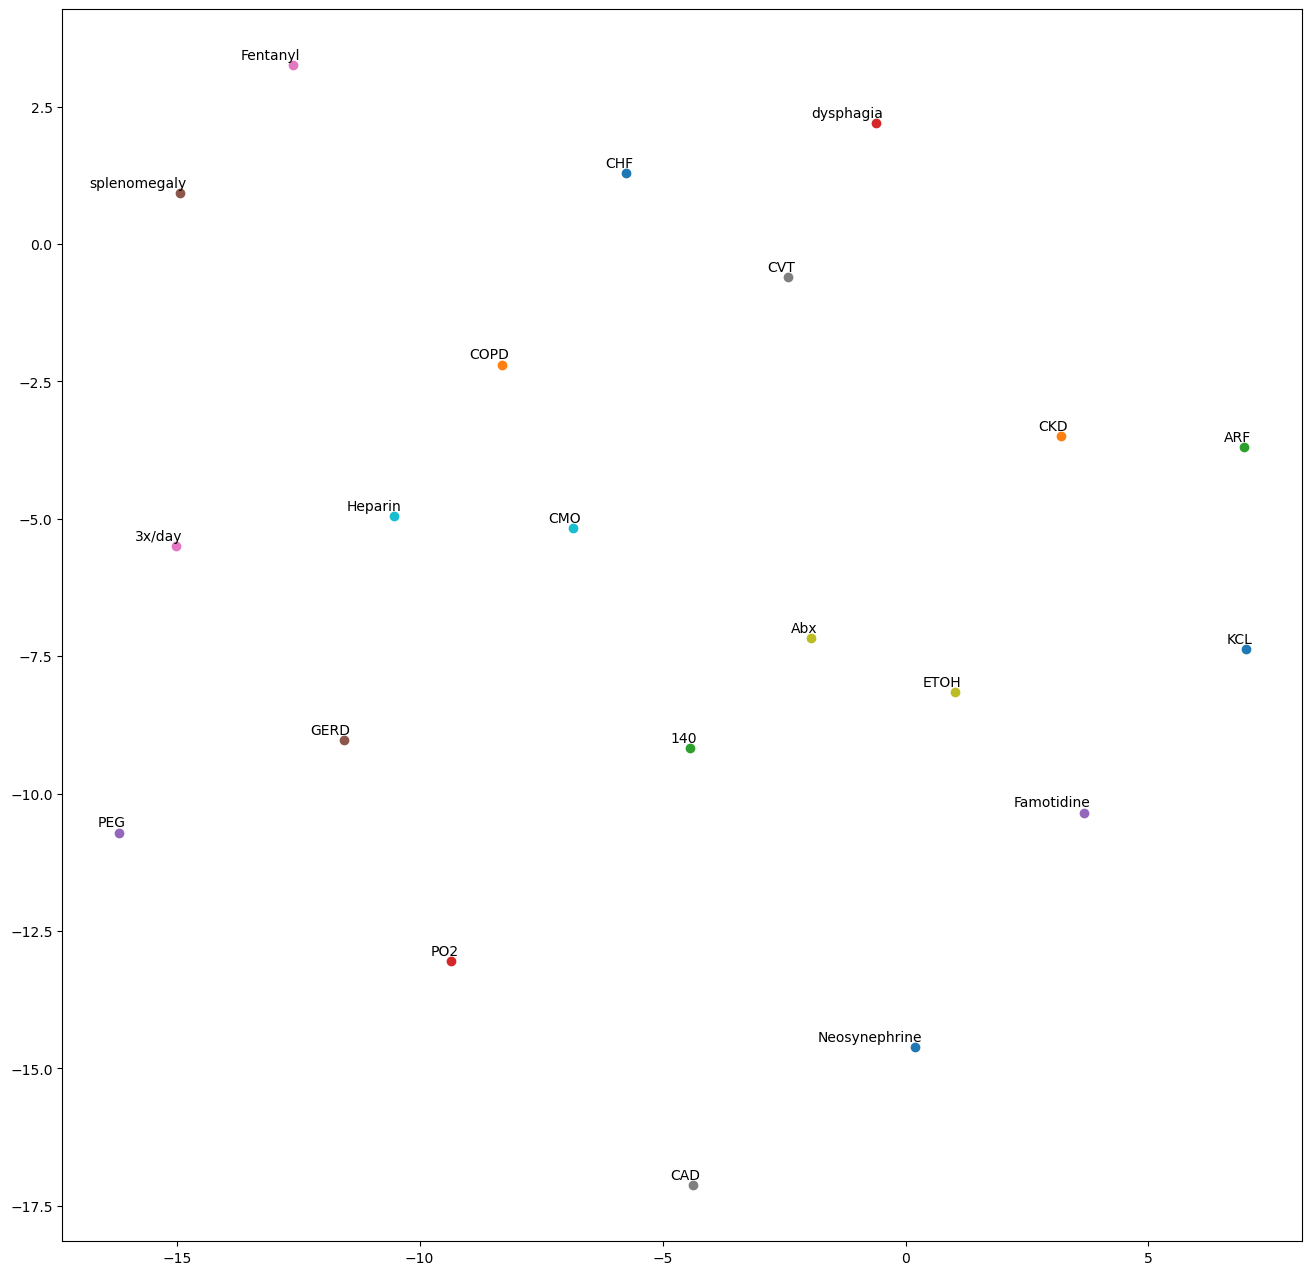

In [31]:
vocabs = model2.wv.index_to_key  # Access vocabulary using index_to_key
new_v = np.array(list(vocabs))
tsne_plot(model1, new_v)

In the above code snippet, a lot of words are skipped as the model was not trained. Hence a pretrained model will work better than the above model

In [32]:
# load pre-trained word2vec embeddings
import gensim
import gensim.downloader as api

info = api.info()  # show info about available models/datasets
pretrained_model= api.load("glove-wiki-gigaword-50")  # download the model and return as object ready for use


# model = gensim.models.KeyedVectors.load_word2vec_format('PubMed-and-PMC-ri.tar.gz', binary=True)

In [33]:
new_corpus_in_pretrained_model = []
for word in new_v:
    if word in pretrained_model.key_to_index:
        new_corpus_in_pretrained_model.append(word)
    else:
        print(word)  # Print out-of-vocabulary words


Calcium
Sodium
Glucose
Glucose Finger Stick
Creatinine
Potassium
Chloride
Magnesium
TCO2
Pt
CHF
COPD
CO2
ARF
Bilirubin
septic shock
Phosphate
PO2
DM2
respiratory distress
liver cirrhosis
PEG
volume overload
HTN
respiratory failure
SCC vallecular
GERD
reglan
Fentanyl
KCl
CAD
Abdominal pain
ETOH
esophageal strictures
PVT, splenomegally & hepatic encephalopathy
d/o
hypoactive BS
30cc/hr +
Heparin
right facial droop
Neosynephrine
urosepsis
CKD
PE
s/p TAH
OSA
pseudomonal
hospitlaization
pneumatosis
respiratory failure s/p trach
Famotidine
Dexamethazone
throat swelling
sublingual bleed
throat edema
supra-therapeutic
CNSD
3x/wk
PEG, XRT
scopalamine
oral cancer s/p PEG
Dilaudid
Lactulose
3x/day
appetite,
C.diff colitis
CVT
flagyl
Diarrhea
q6H
Abx
CMO
hypernatremia
KCL
gastrinoma
hydrocortizone


In [34]:
import numpy as np

def tsne_plot(model, words):
    "Creates a t-SNE model and plots it"
    labels = []
    tokens = []

    for word in words:
        if word in model:
            tokens.append(model[word])
            labels.append(word)
        else:
            print(f"Skipping '{word}' as it is not present in the model's vocabulary.")

    tsne_model = TSNE(perplexity=11, early_exaggeration=12, n_components=2, init='pca', n_iter=1000, random_state=23)
    new_values = tsne_model.fit_transform(np.array(tokens))  # Convert tokens to a NumPy array

    x = []
    y = []
    for value in new_values:
        x.append(value[0])
        y.append(value[1])

    plt.figure(figsize=(16, 16))
    for i in range(len(x)):
        plt.scatter(x[i], y[i])
        plt.annotate(labels[i],
                     xy=(x[i], y[i]),
                     xytext=(5, 2),
                     textcoords='offset points',
                     ha='right',
                     va='bottom')
    plt.show()

/opt/anaconda3/lib/python3.12/site-packages/sklearn/manifold/_t_sne.py:1162: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


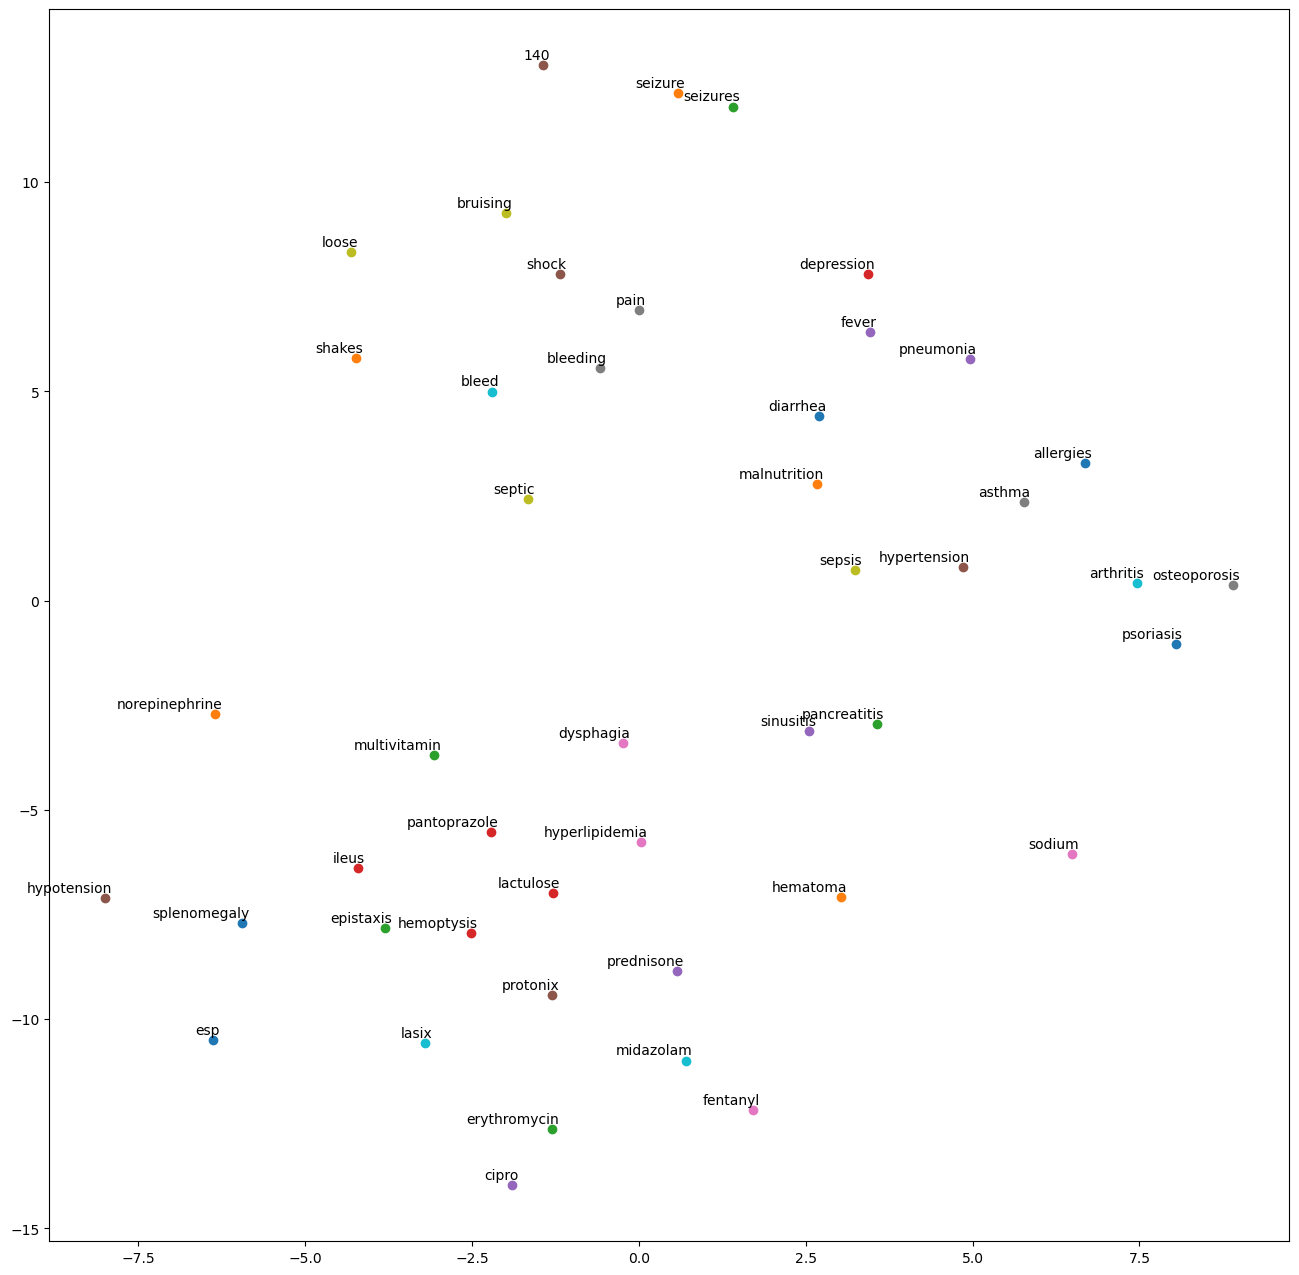

In [35]:
tsne_plot(pretrained_model,new_corpus_in_pretrained_model)